
# ETTh1 – Long-Horizon Forecasting Model Comparison

**Course:** ELE680 – Deep Neural Networks  
**Project:** Group 2 – Long-Horizon Forecasting  
**Dataset:** ETTh1 (Electricity Transformer Temperature)

## Research Question

Does increasing model complexity improve long-horizon time-series forecasting, and how does Reversible Instance Normalization (RevIN) affect Transformer performance?

## Models Evaluated

1. **Persistence** – baseline that uses the last observed target value as the forecast.
2. **DLinear** – a linear model for time-series forecasting.
3. **LSTM** – a recurrent neural network.
4. **Transformer** – an attention-based forecasting model.
5. **Transformer + RevIN** – a Transformer with Reversible Instance Normalization.

## Experimental Setup

- **Input sequence length:** 96 hours
- **Forecasting horizons:** 96, 336, and 720 hours
- **Target variable:** Oil Temperature (OT)
- **Input features:** HUFL, HULL, MUFL, MULL, LUFL, LULL, and OT
- **Evaluation metrics:** Mean Squared Error (MSE) and Mean Absolute Error (MAE)
- **Additional comparisons:** Trainable parameter counts and available training times

The models are compared using their saved experimental results. Lower test MSE and test MAE indicate better forecasting accuracy.

## Notebook Objectives

- Combine the saved results from all five forecasting approaches.
- Compare forecasting accuracy across the three prediction horizons.
- Calculate MSE improvement relative to the Persistence baseline.
- Compare model rankings, parameter counts, and available training times.
- Generate figures and tables to support the project report.
- Discuss the benefits and limitations of the experimental results.


In [1]:

# Step 1: Import libraries and locate saved results

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project directories
results_dir = Path("results")
figures_dir = Path("figures")
models_dir = Path("saved_models")

# Check project folders
print("Results directory exists:", results_dir.exists())
print("Figures directory exists:", figures_dir.exists())
print("Saved models directory exists:", models_dir.exists())

# List available CSV result files
print("\n===== Available Experimental Results =====")

csv_files = sorted(results_dir.glob("*.csv"))

for file in csv_files:
    print(file.name)

print("\nTotal CSV files found:", len(csv_files))

# Check the updated Transformer results
transformer_csv = results_dir / "Transformer_All_Horizons.csv"

if transformer_csv.is_file():
    transformer_results = pd.read_csv(transformer_csv)
    print("\n===== Updated Transformer Results =====")
    print("Rows:", len(transformer_results))
    print("Columns:", transformer_results.columns.tolist())
    display(transformer_results.head())
else:
    print("\nWARNING: Transformer_All_Horizons.csv was not found.")


Results directory exists: True
Figures directory exists: True
Saved models directory exists: True

===== Available Experimental Results =====
DLinear_ETTh1_336h_results.csv
DLinear_ETTh1_720h_results.csv
DLinear_ETTh1_lr0.0001_run2_results.csv
DLinear_ETTh1_results.csv
Final_Model_Comparison_3Models.csv
Final_Model_Comparison_5Models.csv
Final_Model_Rankings_5Models.csv
Forecasting_Model_Comparison.csv
LSTM_336h_simple_results.csv
LSTM_720h_simple_results.csv
LSTM_96h_Validation_Comparison.csv
LSTM_96h_initial_results.csv
LSTM_96h_simple_results.csv
LSTM_All_Horizons_Results.csv
Persistence_All_Horizons.csv
Training_Time_Comparison_Available.csv
Transformer_All_Horizons.csv

Total CSV files found: 17

===== Updated Transformer Results =====
Rows: 6
Columns: ['model', 'input_len', 'pred_len', 'learning_rate', 'val_mse', 'val_mae', 'test_mse', 'test_mae', 'parameters', 'best_epoch', 'epochs_trained', 'training_time_s', 'checkpoint']


,model,input_len,pred_len,learning_rate,val_mse,val_mae,test_mse,test_mae,parameters,best_epoch,epochs_trained,training_time_s,checkpoint
0,Transformer,96,96,0.0001,0.177590,0.337791,0.359840,0.532816,657376,1,6,25.738156,saved_models/Transformer_96h_best.pt
1,Transformer,96,336,0.0001,0.218029,0.381645,0.355421,0.514123,2132176,1,6,25.596656,saved_models/Transformer_336h_best.pt
2,Transformer,96,720,0.0001,0.284155,0.432416,0.459745,0.606255,4491856,1,6,25.272394,saved_models/Transformer_720h_best.pt
3,Transformer + RevIN,96,96,0.0001,0.115752,0.262827,0.059003,0.185151,657376,1,6,25.429973,saved_models/Transformer_RevIN_96h_best.pt
4,Transformer + RevIN,96,336,0.0001,0.153605,0.300240,0.091872,0.236748,2132176,2,7,28.315763,saved_models/Transformer_RevIN_336h_best.pt


In [2]:

# Cell 2: Combine final experimental results
# Persistence, DLinear, LSTM, Transformer, and Transformer + RevIN

import pandas as pd
import numpy as np

# Use the results directory already defined in the notebook.
# If results_dir has not been defined, create it here.
from pathlib import Path

results_dir = Path("results")

# --------------------------------------------------
# 1. Persistence results
# --------------------------------------------------
persistence = pd.read_csv(results_dir / "Persistence_All_Horizons.csv")

persistence = persistence.rename(columns={
    "model": "Model",
    "input_len": "Input_Length",
    "pred_len": "Prediction_Length",
    "val_mse": "Validation_MSE",
    "val_mae": "Validation_MAE",
    "test_mse": "Test_MSE",
    "test_mae": "Test_MAE",
    "parameters": "Parameters"
})

persistence["Model"] = "Persistence"
persistence["Parameters"] = 0


# --------------------------------------------------
# 2. DLinear results
# --------------------------------------------------
dlinear_files = {
    96: "DLinear_ETTh1_lr0.0001_run2_results.csv",
    336: "DLinear_ETTh1_336h_results.csv",
    720: "DLinear_ETTh1_720h_results.csv"
}

dlinear_frames = []

for horizon, filename in dlinear_files.items():
    path = results_dir / filename

    if not path.exists():
        raise FileNotFoundError(f"Missing DLinear results file: {path}")

    df = pd.read_csv(path)

    # Standardize column names
    df = df.rename(columns={
        "model": "Model",
        "input_len": "Input_Length",
        "pred_len": "Prediction_Length",
        "val_mse": "Validation_MSE",
        "val_mae": "Validation_MAE",
        "test_mse": "Test_MSE",
        "test_mae": "Test_MAE",
        "parameters": "Parameters",
        "Trainable_Parameters": "Parameters"
    })

    # Fill in horizon if the CSV does not contain it
    if "Prediction_Length" not in df.columns:
        df["Prediction_Length"] = horizon

    if "Input_Length" not in df.columns:
        df["Input_Length"] = 96

    df["Model"] = "DLinear"
    dlinear_frames.append(df)

dlinear = pd.concat(dlinear_frames, ignore_index=True)


# --------------------------------------------------
# 3. LSTM results
# --------------------------------------------------
lstm = pd.read_csv(results_dir / "LSTM_All_Horizons_Results.csv")

lstm = lstm.rename(columns={
    "model": "Model",
    "input_len": "Input_Length",
    "pred_len": "Prediction_Length",
    "val_mse": "Validation_MSE",
    "val_mae": "Validation_MAE",
    "test_mse": "Test_MSE",
    "test_mae": "Test_MAE",
    "parameters": "Parameters",
    "Trainable_Parameters": "Parameters",
    "training_time_s": "Training_Time_Seconds",
    "Training_Time_Seconds": "Training_Time_Seconds"
})

lstm["Model"] = "LSTM"


# --------------------------------------------------
# 4. Transformer and Transformer + RevIN results
# --------------------------------------------------
transformer = pd.read_csv(
    results_dir / "Transformer_All_Horizons.csv"
)

transformer = transformer.rename(columns={
    "model": "Model",
    "input_len": "Input_Length",
    "pred_len": "Prediction_Length",
    "val_mse": "Validation_MSE",
    "val_mae": "Validation_MAE",
    "test_mse": "Test_MSE",
    "test_mae": "Test_MAE",
    "parameters": "Parameters",
    "training_time_s": "Training_Time_Seconds"
})


# --------------------------------------------------
# 5. Combine all five model groups
# --------------------------------------------------
comparison = pd.concat(
    [persistence, dlinear, lstm, transformer],
    ignore_index=True,
    sort=False
)

# Keep only columns needed for the comparison
required_columns = [
    "Model",
    "Input_Length",
    "Prediction_Length",
    "Validation_MSE",
    "Test_MSE",
    "Test_MAE",
    "Parameters"
]

for column in required_columns:
    if column not in comparison.columns:
        comparison[column] = np.nan

comparison = comparison[required_columns].copy()

# Convert metric and count columns to numeric values
numeric_columns = [
    "Input_Length",
    "Prediction_Length",
    "Validation_MSE",
    "Test_MSE",
    "Test_MAE",
    "Parameters"
]

for column in numeric_columns:
    comparison[column] = pd.to_numeric(
        comparison[column],
        errors="coerce"
    )

comparison = comparison[
    comparison["Prediction_Length"].isin([96, 336, 720])
].copy()

# Keep one row per model and horizon
comparison = comparison.drop_duplicates(
    subset=["Model", "Prediction_Length"],
    keep="last"
)

# Sort consistently
model_order = {
    "Persistence": 0,
    "DLinear": 1,
    "LSTM": 2,
    "Transformer": 3,
    "Transformer + RevIN": 4
}

comparison["Model_Order"] = comparison["Model"].map(model_order)

comparison = (
    comparison
    .sort_values(["Prediction_Length", "Model_Order"])
    .drop(columns="Model_Order")
    .reset_index(drop=True)
)

print("===== Final Model Comparison =====")
display(comparison.round(6))

print("\n===== Experiment Coverage =====")

expected_pairs = {
    (model, horizon)
    for model in model_order
    for horizon in [96, 336, 720]
}

actual_pairs = set(
    zip(comparison["Model"], comparison["Prediction_Length"])
)

print("Expected experiments:", len(expected_pairs))
print("Experiments found:", len(actual_pairs))
print("Missing experiments:", sorted(expected_pairs - actual_pairs))

print("\n===== Missing Parameter Counts =====")
display(
    comparison[
        comparison["Parameters"].isna()
    ][["Model", "Prediction_Length", "Parameters"]]
)


===== Final Model Comparison =====


,Model,Input_Length,Prediction_Length,Validation_MSE,Test_MSE,Test_MAE,Parameters
0,Persistence,96,96,0.137300,0.069300,0.203300,0
1,DLinear,96,96,0.096491,0.064651,0.187502,18624
2,LSTM,96,96,0.260937,0.501855,0.645748,8416
3,Transformer,96,96,0.177590,0.359840,0.532816,657376
4,Transformer + RevIN,96,96,0.115752,0.059003,0.185151,657376
5,Persistence,96,336,0.185977,0.113274,0.265204,0
6,DLinear,96,336,0.128641,0.095971,0.240374,65184
7,LSTM,96,336,0.283172,0.612728,0.737606,16336
8,Transformer,96,336,0.218029,0.355421,0.514123,2132176
9,Transformer + RevIN,96,336,0.153605,0.091872,0.236748,2132176



===== Experiment Coverage =====
Expected experiments: 15
Experiments found: 15
Missing experiments: []

===== Missing Parameter Counts =====


,Model,Prediction_Length,Parameters


In [3]:

# Cell 3: Verify model and forecasting-horizon coverage

expected_models = [
    "Persistence",
    "DLinear",
    "LSTM",
    "Transformer",
    "Transformer + RevIN"
]

expected_horizons = [96, 336, 720]

print("===== Model and Horizon Coverage =====")

for model_name in expected_models:
    model_rows = comparison[
        comparison["Model"] == model_name
    ]

    found_horizons = sorted(
        model_rows["Prediction_Length"]
        .dropna()
        .astype(int)
        .unique()
        .tolist()
    )

    missing_horizons = [
        horizon
        for horizon in expected_horizons
        if horizon not in found_horizons
    ]

    print(f"\n{model_name}")
    print("Available horizons:", found_horizons)
    print("Missing horizons:", missing_horizons or "None")

print("\n===== Test MSE by Model and Horizon =====")

mse_table = comparison.pivot(
    index="Model",
    columns="Prediction_Length",
    values="Test_MSE"
).reindex(
    index=expected_models,
    columns=expected_horizons
)

display(mse_table.round(6))

print("\n===== Test MAE by Model and Horizon =====")

mae_table = comparison.pivot(
    index="Model",
    columns="Prediction_Length",
    values="Test_MAE"
).reindex(
    index=expected_models,
    columns=expected_horizons
)

display(mae_table.round(6))

print("\n===== Coverage Summary =====")

expected_count = len(expected_models) * len(expected_horizons)
actual_count = len(comparison)

print("Expected model-horizon combinations:", expected_count)
print("Rows in comparison:", actual_count)

print("\nMissing metric values:")
display(
    comparison[
        ["Validation_MSE", "Test_MSE", "Test_MAE", "Parameters"]
    ].isna().sum().rename("Missing values").to_frame()
)


===== Model and Horizon Coverage =====

Persistence
Available horizons: [96, 336, 720]
Missing horizons: None

DLinear
Available horizons: [96, 336, 720]
Missing horizons: None

LSTM
Available horizons: [96, 336, 720]
Missing horizons: None

Transformer
Available horizons: [96, 336, 720]
Missing horizons: None

Transformer + RevIN
Available horizons: [96, 336, 720]
Missing horizons: None

===== Test MSE by Model and Horizon =====


Prediction_Length,96,336,720
Model,,,
Persistence,0.069300,0.113274,0.129179
DLinear,0.064651,0.095971,0.167763
LSTM,0.501855,0.612728,0.857829
Transformer,0.359840,0.355421,0.459745
Transformer + RevIN,0.059003,0.091872,0.128817



===== Test MAE by Model and Horizon =====


Prediction_Length,96,336,720
Model,,,
Persistence,0.203300,0.265204,0.283409
DLinear,0.187502,0.240374,0.335462
LSTM,0.645748,0.737606,0.876643
Transformer,0.532816,0.514123,0.606255
Transformer + RevIN,0.185151,0.236748,0.282477



===== Coverage Summary =====
Expected model-horizon combinations: 15
Rows in comparison: 15

Missing metric values:


,Missing values
Validation_MSE,0
Test_MSE,0
Test_MAE,0
Parameters,0


In [4]:

# Inspect the result files for DLinear and LSTM

files_to_check = [
    "DLinear_ETTh1_results.csv",
    "DLinear_ETTh1_336h_results.csv",
    "DLinear_ETTh1_720h_results.csv",
    "LSTM_All_Horizons_Results.csv",
    "LSTM_96h_initial_results.csv",
    "LSTM_96h_simple_results.csv",
    "LSTM_336h_simple_results.csv",
    "LSTM_720h_simple_results.csv",
]

for filename in files_to_check:
    path = results_dir / filename

    print(f"\n{'=' * 60}")
    print(f"File: {filename}")

    if path.exists():
        df = pd.read_csv(path)
        print("Columns:", df.columns.tolist())
        print("Rows:", len(df))
        display(df.head(3))
    else:
        print("FILE NOT FOUND")



File: DLinear_ETTh1_results.csv
Columns: ['Model', 'Input_Length', 'Prediction_Length', 'Validation_MSE', 'Validation_MAE', 'Test_MSE', 'Test_MAE', 'Best_Epoch', 'Epochs_Trained', 'Learning_Rate', 'Parameters', 'Training_Time_Seconds']
Rows: 1


,Model,Input_Length,Prediction_Length,Validation_MSE,Validation_MAE,Test_MSE,Test_MAE,Best_Epoch,Epochs_Trained,Learning_Rate,Parameters,Training_Time_Seconds
0,DLinear,96,96,0.096711,0.243047,0.071206,0.197362,2,7,0.001,18624,6.24



File: DLinear_ETTh1_336h_results.csv
Columns: ['model', 'input_len', 'pred_len', 'learning_rate', 'parameters', 'val_mse', 'val_mae', 'test_mse', 'test_mae']
Rows: 1


,model,input_len,pred_len,learning_rate,parameters,val_mse,val_mae,test_mse,test_mae
0,DLinear,96,336,0.0001,65184,0.128641,0.286215,0.095971,0.240374



File: DLinear_ETTh1_720h_results.csv
Columns: ['model', 'input_len', 'pred_len', 'learning_rate', 'parameters', 'val_mse', 'val_mae', 'test_mse', 'test_mae']
Rows: 1


...

,Model,Experiment,Input_Length,Prediction_Length,Hidden_Size,LSTM_Layers,Dropout,Learning_Rate,Batch_Size,Seed,Best_Epoch,Validation_MSE,Test_MSE,Test_MAE,Training_Time_Seconds,Trainable_Parameters
0,LSTM,Simple,96,96,32,1,0.0,0.0005,32,42,1,0.260937,0.501855,0.645748,8.812514,8416



File: LSTM_336h_simple_results.csv
Columns: ['Model', 'Experiment', 'Input_Length', 'Prediction_Length', 'Hidden_Size', 'LSTM_Layers', 'Dropout', 'Learning_Rate', 'Batch_Size', 'Seed', 'Best_Epoch', 'Validation_MSE', 'Test_MSE', 'Test_MAE', 'Training_Time_Seconds', 'Trainable_Parameters']
Rows: 1


,Model,Experiment,Input_Length,Prediction_Length,Hidden_Size,LSTM_Layers,Dropout,Learning_Rate,Batch_Size,Seed,Best_Epoch,Validation_MSE,Test_MSE,Test_MAE,Training_Time_Seconds,Trainable_Parameters
0,LSTM,Simple,96,336,32,1,0.0,0.0005,32,42,3,0.283172,0.612728,0.737606,11.479456,16336



File: LSTM_720h_simple_results.csv
Columns: ['Model', 'Experiment', 'Input_Length', 'Prediction_Length', 'Hidden_Size', 'LSTM_Layers', 'Dropout', 'Learning_Rate', 'Batch_Size', 'Seed', 'Best_Epoch', 'Validation_MSE', 'Test_MSE', 'Test_MAE', 'Training_Time_Seconds', 'Trainable_Parameters']
Rows: 1


,Model,Experiment,Input_Length,Prediction_Length,Hidden_Size,LSTM_Layers,Dropout,Learning_Rate,Batch_Size,Seed,Best_Epoch,Validation_MSE,Test_MSE,Test_MAE,Training_Time_Seconds,Trainable_Parameters
0,LSTM,Simple,96,720,32,1,0.0,0.0005,32,42,3,0.373152,0.857829,0.876643,11.089589,29008


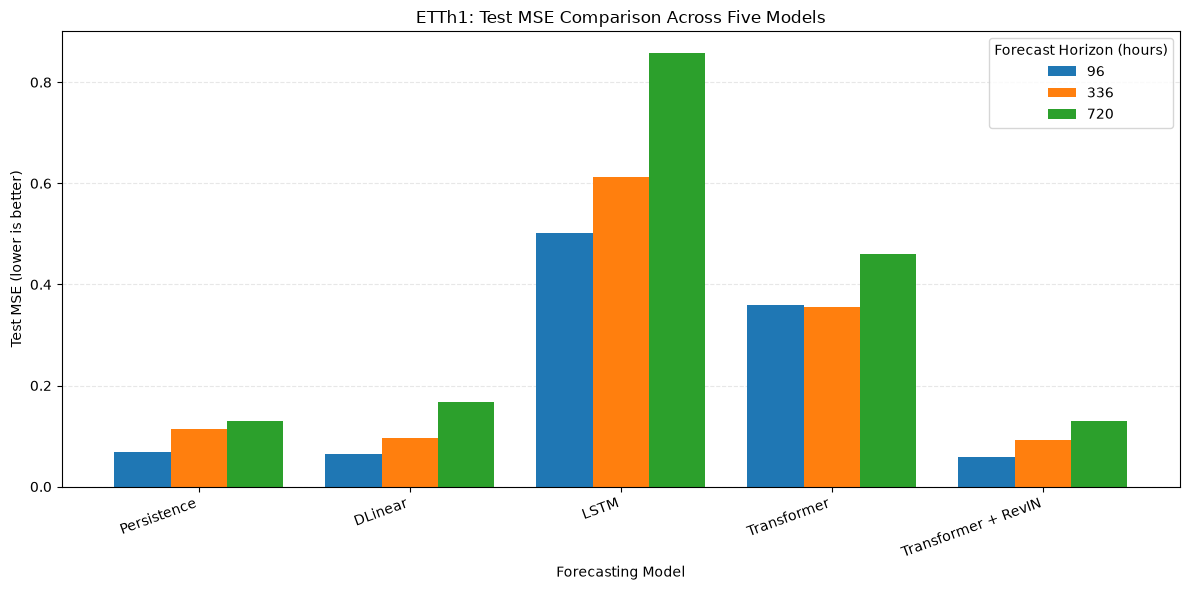

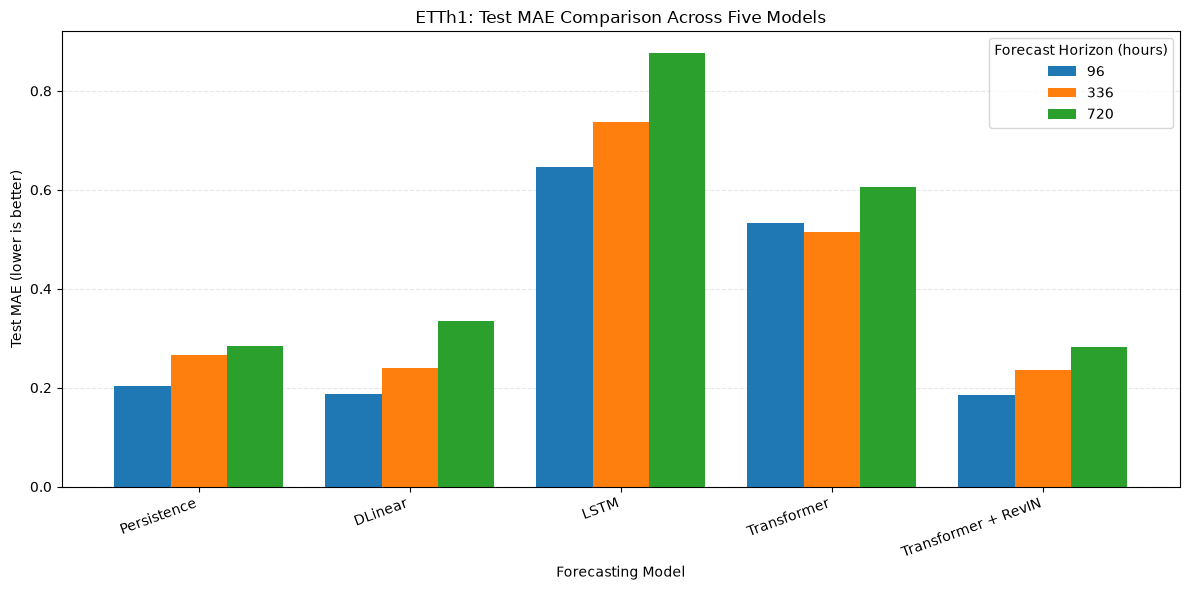

Saved Test MSE graph: figures/Model_Comparison_Test_MSE.png
Saved Test MAE graph: figures/Model_Comparison_Test_MAE.png


In [5]:

# Step 4: Final comparison graphs for all five forecasting models

import matplotlib.pyplot as plt

model_order = [
    "Persistence",
    "DLinear",
    "LSTM",
    "Transformer",
    "Transformer + RevIN"
]

horizons = [96, 336, 720]

# Arrange Test MSE and Test MAE results
mse_table = comparison.pivot(
    index="Model",
    columns="Prediction_Length",
    values="Test_MSE"
).reindex(index=model_order, columns=horizons)

mae_table = comparison.pivot(
    index="Model",
    columns="Prediction_Length",
    values="Test_MAE"
).reindex(index=model_order, columns=horizons)

# Check that all expected values are available
if mse_table.isna().any().any() or mae_table.isna().any().any():
    print("WARNING: Some model or horizon results are missing.")
    print("Test MSE:")
    display(mse_table)
    print("Test MAE:")
    display(mae_table)

else:
    figures_dir.mkdir(parents=True, exist_ok=True)

    # Graph 1: Test MSE
    ax = mse_table.plot(
        kind="bar",
        figsize=(12, 6),
        width=0.8
    )

    ax.set_title("ETTh1: Test MSE Comparison Across Five Models")
    ax.set_xlabel("Forecasting Model")
    ax.set_ylabel("Test MSE (lower is better)")
    ax.set_xticklabels(model_order, rotation=20, ha="right")
    ax.legend(title="Forecast Horizon (hours)")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()

    mse_path = figures_dir / "Model_Comparison_Test_MSE.png"
    plt.savefig(mse_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    # Graph 2: Test MAE
    ax = mae_table.plot(
        kind="bar",
        figsize=(12, 6),
        width=0.8
    )

    ax.set_title("ETTh1: Test MAE Comparison Across Five Models")
    ax.set_xlabel("Forecasting Model")
    ax.set_ylabel("Test MAE (lower is better)")
    ax.set_xticklabels(model_order, rotation=20, ha="right")
    ax.legend(title="Forecast Horizon (hours)")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()

    mae_path = figures_dir / "Model_Comparison_Test_MAE.png"
    plt.savefig(mae_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved Test MSE graph:", mse_path)
    print("Saved Test MAE graph:", mae_path)


In [6]:
# Final model rankings using all five models from Cell 2

ranking_df = comparison.copy()

# Rank models separately for each forecast horizon (rank 1 = lowest test MSE)
ranking_df["MSE_Rank"] = (
    ranking_df.groupby("Prediction_Length")["Test_MSE"]
    .rank(method="min", ascending=True)
    .astype("Int64")
)

# Calculate improvement over Persistence: positive means lower MSE than Persistence
persistence_mse = (
    ranking_df.loc[ranking_df["Model"] == "Persistence"]
    .set_index("Prediction_Length")["Test_MSE"]
)

baseline_for_row = ranking_df["Prediction_Length"].map(persistence_mse)
ranking_df["MSE_Improvement_%"] = (
    (baseline_for_row - ranking_df["Test_MSE"]) / baseline_for_row * 100
)

final_ranking = (
    ranking_df.sort_values(["Prediction_Length", "MSE_Rank", "Model"])
    [["Prediction_Length", "Model", "Test_MSE", "Test_MAE", "MSE_Improvement_%", "MSE_Rank"]]
    .reset_index(drop=True)
)

display(final_ranking.round(4))

ranking_path = results_dir / "Final_Model_Rankings_5Models.csv"
final_ranking.to_csv(ranking_path, index=False)
print(f"Saved: {ranking_path}")


,Prediction_Length,Model,Test_MSE,Test_MAE,MSE_Improvement_%,MSE_Rank
0,96,Transformer + RevIN,0.0590,0.1852,14.8582,1
1,96,DLinear,0.0647,0.1875,6.7088,2
2,96,Persistence,0.0693,0.2033,0.0000,3
3,96,Transformer,0.3598,0.5328,-419.2496,4
4,96,LSTM,0.5019,0.6457,-624.1773,5
5,336,Transformer + RevIN,0.0919,0.2367,18.8936,1
6,336,DLinear,0.0960,0.2404,15.2750,2
7,336,Persistence,0.1133,0.2652,0.0000,3
8,336,Transformer,0.3554,0.5141,-213.7708,4
9,336,LSTM,0.6127,0.7376,-440.9254,5


Saved: results/Final_Model_Rankings_5Models.csv


===== Parameter Counts =====


Model,Persistence,DLinear,LSTM,Transformer,Transformer + RevIN
Prediction_Length,,,,,
96,0,18624,8416,657376,657376
336,0,65184,16336,2132176,2132176
720,0,139680,29008,4491856,4491856


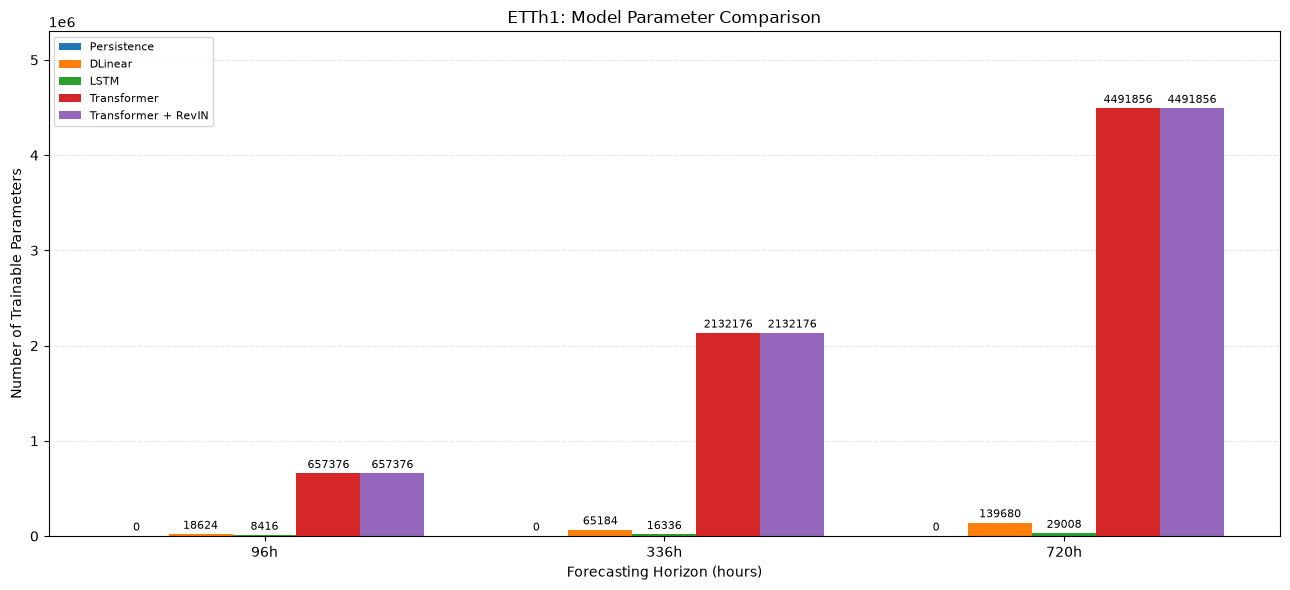

Figure saved to: figures/Model_Comparison_Parameters.png


In [7]:

# Step 8: Compare model complexity using parameter counts

models = [
    "Persistence",
    "DLinear",
    "LSTM",
    "Transformer",
    "Transformer + RevIN"
]

horizons = [96, 336, 720]

# Use the combined comparison table from Step 3
parameter_table = comparison.pivot(
    index="Prediction_Length",
    columns="Model",
    values="Parameters"
).reindex(index=horizons, columns=models)

print("===== Parameter Counts =====")
display(parameter_table)

if parameter_table.isna().any().any():
    print(
        "Some parameter counts are missing. "
        "Check the output above before interpreting the graph."
    )
else:
    fig, ax = plt.subplots(figsize=(13, 6))

    x = np.arange(len(horizons))
    bar_width = 0.16

    for i, model in enumerate(models):
        bars = ax.bar(
            x + (i - (len(models) - 1) / 2) * bar_width,
            parameter_table[model],
            width=bar_width,
            label=model
        )

        ax.bar_label(
            bars,
            fmt="%.0f",
            padding=2,
            fontsize=8
        )

    ax.set_xticks(x)
    ax.set_xticklabels([f"{h}h" for h in horizons])
    ax.set_xlabel("Forecasting Horizon (hours)")
    ax.set_ylabel("Number of Trainable Parameters")
    ax.set_title("ETTh1: Model Parameter Comparison")

    ax.legend(fontsize=8)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.set_ylim(0, parameter_table.to_numpy().max() * 1.18)

    plt.tight_layout()

    figures_dir.mkdir(parents=True, exist_ok=True)
    figure_path = figures_dir / "Model_Comparison_Parameters.png"

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"Figure saved to: {figure_path}")


In [8]:
# Step 9: Compare available training times
# Uses saved CSV results plus the DLinear times reported from Dilhani's notebook output.
# No models are retrained in this cell.

import pandas as pd
from pathlib import Path

results_dir = Path("results")
training_time_files = {
    "DLinear": [
        "DLinear_ETTh1_lr0.0001_run2_results.csv",
        "DLinear_ETTh1_336h_results.csv",
        "DLinear_ETTh1_720h_results.csv",
    ],
    "LSTM": ["LSTM_All_Horizons_Results.csv"],
    "Transformer": ["Transformer_All_Horizons.csv"],
}

time_frames = []
for model_name, filenames in training_time_files.items():
    for filename in filenames:
        file_path = results_dir / filename
        if not file_path.exists():
            print(f"Skipping missing file: {filename}")
            continue

        df = pd.read_csv(file_path)
        normalized = {str(c).strip().lower(): c for c in df.columns}
        time_column = next(
            (normalized[k] for k in ["training_time_s", "training_time_seconds", "training_time", "training_time_sec"] if k in normalized),
            None,
        )
        horizon_column = next(
            (normalized[k] for k in ["pred_len", "prediction_length", "prediction_horizon", "horizon"] if k in normalized),
            None,
        )
        model_column = next(
            (normalized[k] for k in ["model", "model_name"] if k in normalized),
            None,
        )

        if time_column is None or horizon_column is None:
            print(f"No recognized training-time/horizon column in {filename}; skipping it.")
            print("Available columns:", df.columns.tolist())
            continue

        out = pd.DataFrame({
            "Prediction_Length": pd.to_numeric(df[horizon_column], errors="coerce"),
            "Training_Time_Seconds": pd.to_numeric(df[time_column], errors="coerce"),
        })
        # Keep true model names for Transformer and Transformer + RevIN.
        if model_name == "Transformer" and model_column is not None:
            out["Model"] = df[model_column].astype(str).str.strip().replace({
                "Transformer_RevIN": "Transformer + RevIN",
                "Transformer with RevIN": "Transformer + RevIN",
                "Transformer+RevIN": "Transformer + RevIN",
            })
        else:
            out["Model"] = model_name
        out["Source_File"] = filename
        time_frames.append(out[["Model", "Prediction_Length", "Training_Time_Seconds", "Source_File"]])

# These DLinear training times were reported in the review as values printed by
# Dilhani's DLinear notebook. Verify against her original outputs before citing them.
dlinear_reported_times = pd.DataFrame({
    "Model": ["DLinear", "DLinear", "DLinear"],
    "Prediction_Length": [96, 336, 720],
    "Training_Time_Seconds": [17.22, 13.38, 15.81],
    "Source_File": ["Reported notebook output (verify)"] * 3,
})
time_frames.append(dlinear_reported_times)

# Persistence is a non-trained baseline; record zero training time by definition.
time_frames.append(pd.DataFrame({
    "Model": ["Persistence", "Persistence", "Persistence"],
    "Prediction_Length": [96, 336, 720],
    "Training_Time_Seconds": [0.0, 0.0, 0.0],
    "Source_File": ["Non-trained baseline"] * 3,
}))

if time_frames:
    training_time_comparison = pd.concat(time_frames, ignore_index=True)
    training_time_comparison["Prediction_Length"] = pd.to_numeric(training_time_comparison["Prediction_Length"], errors="coerce")
    training_time_comparison["Training_Time_Seconds"] = pd.to_numeric(training_time_comparison["Training_Time_Seconds"], errors="coerce")
    # Remove duplicate model/horizon entries, preferring the explicit reported DLinear values.
    training_time_comparison["_priority"] = training_time_comparison["Source_File"].eq("Reported notebook output (verify)").astype(int)
    training_time_comparison = (
        training_time_comparison.sort_values("_priority", ascending=False)
        .drop_duplicates(["Model", "Prediction_Length"], keep="first")
        .drop(columns="_priority")
        .sort_values(["Prediction_Length", "Model"])
        .reset_index(drop=True)
    )
    print("===== Training-Time Results =====")
    display(training_time_comparison.round(2))
    output_path = results_dir / "Training_Time_Comparison_Available.csv"
    training_time_comparison.to_csv(output_path, index=False)
    print(f"Saved to: {output_path}")
    print("Note: verify the three DLinear times against Dilhani's original notebook output before final submission.")


No recognized training-time/horizon column in DLinear_ETTh1_lr0.0001_run2_results.csv; skipping it.
Available columns: ['Model', 'Experiment', 'Input_Length', 'Prediction_Length', 'Validation_MSE', 'Validation_MAE', 'Test_MSE', 'Test_MAE', 'Best_Epoch', 'Epochs_Trained', 'Learning_Rate', 'Parameters', 'Checkpoint']
No recognized training-time/horizon column in DLinear_ETTh1_336h_results.csv; skipping it.
Available columns: ['model', 'input_len', 'pred_len', 'learning_rate', 'parameters', 'val_mse', 'val_mae', 'test_mse', 'test_mae']
No recognized training-time/horizon column in DLinear_ETTh1_720h_results.csv; skipping it.
Available columns: ['model', 'input_len', 'pred_len', 'learning_rate', 'parameters', 'val_mse', 'val_mae', 'test_mse', 'test_mae']
===== Training-Time Results =====


,Model,Prediction_Length,Training_Time_Seconds,Source_File
0,DLinear,96,17.22,Reported notebook output (verify)
1,LSTM,96,8.81,LSTM_All_Horizons_Results.csv
2,Persistence,96,0.00,Non-trained baseline
3,Transformer,96,25.74,Transformer_All_Horizons.csv
4,Transformer + RevIN,96,25.43,Transformer_All_Horizons.csv
5,DLinear,336,13.38,Reported notebook output (verify)
6,LSTM,336,11.48,LSTM_All_Horizons_Results.csv
7,Persistence,336,0.00,Non-trained baseline
8,Transformer,336,25.60,Transformer_All_Horizons.csv
9,Transformer + RevIN,336,28.32,Transformer_All_Horizons.csv


Saved to: results/Training_Time_Comparison_Available.csv
Note: verify the three DLinear times against Dilhani's original notebook output before final submission.


In [9]:
# Step 10: Create the final consolidated comparison CSV
# Uses saved model results and the training-time table from Cell 8; no retraining.

import pandas as pd
import numpy as np
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
final_comparison = comparison.copy()

training_time_path = results_dir / "Training_Time_Comparison_Available.csv"
if training_time_path.exists():
    training_times = pd.read_csv(training_time_path)
    training_times["Model"] = training_times["Model"].astype(str).str.strip().replace({
        "Transformer_RevIN": "Transformer + RevIN",
        "Transformer with RevIN": "Transformer + RevIN",
        "Transformer+RevIN": "Transformer + RevIN",
    })
    training_times["Prediction_Length"] = pd.to_numeric(training_times["Prediction_Length"], errors="coerce")
    training_times["Training_Time_Seconds"] = pd.to_numeric(training_times["Training_Time_Seconds"], errors="coerce")
    training_times = training_times.drop_duplicates(["Model", "Prediction_Length"], keep="first")
    final_comparison = final_comparison.merge(
        training_times[["Model", "Prediction_Length", "Training_Time_Seconds"]],
        on=["Model", "Prediction_Length"],
        how="left",
    )
else:
    print("Training-time table not found. Run Cell 8 before this cell.")
    final_comparison["Training_Time_Seconds"] = np.nan

# Calculate improvement over Persistence for each horizon (positive = lower MSE).
persistence_mse = (
    final_comparison.loc[final_comparison["Model"] == "Persistence", ["Prediction_Length", "Test_MSE"]]
    .drop_duplicates("Prediction_Length")
    .set_index("Prediction_Length")["Test_MSE"]
)
baseline_for_row = final_comparison["Prediction_Length"].map(persistence_mse)
final_comparison["MSE_Improvement_%"] = (baseline_for_row - final_comparison["Test_MSE"]) / baseline_for_row * 100

final_comparison["MSE_Rank"] = final_comparison.groupby("Prediction_Length")["Test_MSE"].rank(method="min", ascending=True).astype("Int64")
final_comparison = final_comparison.sort_values(["Prediction_Length", "MSE_Rank", "Model"]).reset_index(drop=True)

output_path = results_dir / "Final_Model_Comparison_5Models.csv"
final_comparison.to_csv(output_path, index=False)
print(f"Final comparison saved to: {output_path}")
print(f"Number of rows: {len(final_comparison)}")
display(final_comparison.round(6))

print("\nNumber of models per forecasting horizon:")
display(final_comparison.groupby("Prediction_Length")["Model"].nunique().rename("Number_of_Models").to_frame())

print("\nMissing training times:")
display(final_comparison.loc[final_comparison["Training_Time_Seconds"].isna(), ["Model", "Prediction_Length", "Training_Time_Seconds"]])


Final comparison saved to: results/Final_Model_Comparison_5Models.csv
Number of rows: 15


,Model,Input_Length,Prediction_Length,Validation_MSE,Test_MSE,Test_MAE,Parameters,Training_Time_Seconds,MSE_Improvement_%,MSE_Rank
0,Transformer + RevIN,96,96,0.115752,0.059003,0.185151,657376,25.429973,14.858170,1
1,DLinear,96,96,0.096491,0.064651,0.187502,18624,17.220000,6.708807,2
2,Persistence,96,96,0.137300,0.069300,0.203300,0,0.000000,0.000000,3
3,Transformer,96,96,0.177590,0.359840,0.532816,657376,25.738156,-419.249605,4
4,LSTM,96,96,0.260937,0.501855,0.645748,8416,8.812514,-624.177330,5
5,Transformer + RevIN,96,336,0.153605,0.091872,0.236748,2132176,28.315763,18.893627,1
6,DLinear,96,336,0.128641,0.095971,0.240374,65184,13.380000,15.275010,2
7,Persistence,96,336,0.185977,0.113274,0.265204,0,0.000000,0.000000,3
8,Transformer,96,336,0.218029,0.355421,0.514123,2132176,25.596656,-213.770815,4
9,LSTM,96,336,0.283172,0.612728,0.737606,16336,11.479456,-440.925414,5



Number of models per forecasting horizon:


,Number_of_Models
Prediction_Length,
96,5
336,5
720,5



Missing training times:


,Model,Prediction_Length,Training_Time_Seconds


## Experimental Findings and Discussion

### 1. Forecasting Accuracy

Five forecasting approaches were evaluated on ETTh1: Persistence, DLinear, LSTM, Transformer, and Transformer + RevIN. All experiments used a 96-hour input window and prediction horizons of 96, 336, and 720 hours.

| Prediction horizon | Persistence test MSE | DLinear test MSE | LSTM test MSE | Transformer test MSE | Transformer + RevIN test MSE |
|---|---:|---:|---:|---:|---:|
| 96 hours | 0.0693 | 0.0647 | 0.5019 | 0.3598 | **0.0590** |
| 336 hours | 0.1133 | 0.0960 | 0.6127 | 0.3554 | **0.0919** |
| 720 hours | 0.1292 | 0.1678 | 0.8578 | 0.4597 | **0.1288** |

Transformer + RevIN had the lowest **test** MSE at all three horizons in this run. Compared with Persistence, its test MSE was lower by approximately 14.86% at 96 hours, 18.89% at 336 hours, and 0.28% at 720 hours. The 720-hour difference is very small and should not be treated as strong evidence of superiority from a single run.

Validation and test results do not tell exactly the same story. The supplied validation results show lower validation MSE for DLinear than Transformer + RevIN at each horizon (DLinear: 0.0965, 0.1286, 0.1569; Transformer + RevIN: 0.1158, 0.1536, 0.2171). Thus, although Transformer + RevIN ranks first on test MSE in this run, DLinear performed better on validation. This difference is a reason to interpret the final ranking cautiously, rather than claim that one model is clearly superior.

### 2. Effect of RevIN

The standard Transformer and Transformer + RevIN have the same reported trainable parameter counts, but their test errors differ substantially. This suggests that normalization may have helped the Transformer handle distribution changes in this dataset. However, these experiments do not establish that RevIN will provide the same benefit for every dataset or configuration. A DLinear + RevIN experiment and repeated runs with different random seeds would provide stronger evidence.

### 3. LSTM Performance

The evaluated LSTM configuration produced the highest test MSE at all three horizons: approximately 0.5019, 0.6127, and 0.8578. This indicates that this selected LSTM configuration was less effective than the other evaluated approaches in these experiments; it does not mean that LSTMs are generally unsuitable for time-series forecasting.

### 4. Model Complexity

Persistence has no trainable parameters. The parameter counts reported for the other models are:

| Model | 96-hour horizon | 336-hour horizon | 720-hour horizon |
|---|---:|---:|---:|
| DLinear | 18,624 | 65,184 | 139,680 |
| LSTM | 8,416 | 16,336 | 29,008 |
| Transformer | 657,376 | 2,132,176 | 4,491,856 |
| Transformer + RevIN | 657,376 | 2,132,176 | 4,491,856 |

The standard Transformer has substantially more parameters than DLinear but does not achieve the best forecasting accuracy here. Adding RevIN does not change the parameter count, yet the Transformer + RevIN variant performs much better than the plain Transformer. This suggests that model design and normalization mattered in these experiments more than simply increasing parameter count. Parameter count alone does not describe all computational costs, memory use, or inference speed.

### 5. Training-Time Comparison

The currently recorded or reported training times are approximately:

- **DLinear:** 17.22 seconds (96h, learning rate 0.0001), 13.38 seconds (336h), and 15.81 seconds (720h). These values were reported from Dilhani's notebook output and should be checked against the original output before final submission.
- **LSTM:** approximately 8.81–11.48 seconds.
- **Transformer:** approximately 25.27–25.74 seconds.
- **Transformer + RevIN:** approximately 23.53–28.32 seconds.
- **Persistence:** no model training is required; its recorded training time is set to 0 seconds by definition.

Training-time measurements depend on hardware, implementation, and configuration, so treat them as measurements from these experiments rather than universal model costs.

### 6. Limitations

- The experiments use only the ETTh1 dataset.
- Each model and horizon is represented by a selected configuration rather than a systematic search over many configurations.
- The results do not include repeated runs across multiple random seeds.
- MSE and MAE are calculated on the standardized OT target, so they are not expressed in original temperature units.
- The comparison does not include a DLinear + RevIN variant.
- Validation and test rankings differ, and the test-set advantage of Transformer + RevIN over Persistence at 720 hours is very small.
- The reported DLinear training times should be verified against Dilhani's original notebook output before submission.

### 7. Overall Conclusion

On the test set, Transformer + RevIN achieved the lowest MSE at all three horizons, but the margins are small (0.0590 versus 0.0647 for DLinear at 96 hours; 0.1288 versus 0.1292 for Persistence at 720 hours). On the validation set, DLinear performed better than Transformer + RevIN at every horizon. We therefore consider Transformer + RevIN and DLinear competitive in these experiments rather than concluding that one is clearly superior.

The plain Transformer, with up to about 4.5 million parameters (around 32 times the 720-hour DLinear parameter count), performed much worse than Persistence. The same Transformer architecture became competitive after adding RevIN, which does not increase the parameter count. This indicates that handling distribution shift and normalization may matter more than model complexity alone. Further repeated runs, additional datasets, and a DLinear + RevIN comparison are needed to test whether these findings generalize.


In [10]:

# Step 12.1: Verify final comparison files and figures

import pandas as pd
from pathlib import Path

results_dir = Path("results")
figures_dir = Path("figures")

print("===== Folder Verification =====")
print("Results folder exists:", results_dir.exists())
print("Figures folder exists:", figures_dir.exists())

# Check the final CSV in the results folder
expected_result_files = [
    results_dir / "Final_Model_Comparison_5Models.csv",
    results_dir / "Training_Time_Comparison_Available.csv",
]

print("\n===== Results Files =====")

for file_path in expected_result_files:
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"[{status}] {file_path}")

# Check only figures generated by the current comparison workflow
expected_figure_files = [
    figures_dir / "Model_Comparison_Test_MSE.png",
    figures_dir / "Model_Comparison_Test_MAE.png",
    figures_dir / "Model_Comparison_Parameters.png",
]

print("\n===== Figure Files =====")

for file_path in expected_figure_files:
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"[{status}] {file_path}")

# Verify the final consolidated CSV
csv_path = results_dir / "Final_Model_Comparison_5Models.csv"

if csv_path.exists():
    final_df = pd.read_csv(csv_path)

    expected_models = {
        "Persistence",
        "DLinear",
        "LSTM",
        "Transformer",
        "Transformer + RevIN",
    }

    expected_horizons = {96, 336, 720}

    actual_models = set(final_df["Model"].dropna().unique())
    actual_horizons = set(
        pd.to_numeric(
            final_df["Prediction_Length"],
            errors="coerce"
        ).dropna().astype(int).unique()
    )

    print("\n===== Final CSV Verification =====")
    print("Number of rows:", len(final_df))
    print("Models:", sorted(actual_models))
    print("Horizons:", sorted(actual_horizons))

    print("\nRows per model:")
    display(
        final_df.groupby("Model")
        .size()
        .rename("Number of experiments")
        .to_frame()
    )

    print("\nMissing training times:")
    display(
        final_df.loc[
            final_df["Training_Time_Seconds"].isna(),
            ["Model", "Prediction_Length", "Training_Time_Seconds"]
        ]
    )

    print("\n===== Final Checks =====")
    print("Expected 15 rows:", len(final_df) == 15)
    print("All five models present:", actual_models == expected_models)
    print("All three horizons present:", actual_horizons == expected_horizons)

    if len(final_df) == 15 and actual_models == expected_models and actual_horizons == expected_horizons:
        print("The final comparison CSV passed the basic coverage checks.")
    else:
        print("WARNING: Check the final CSV for missing or extra experiments.")


===== Folder Verification =====
Results folder exists: True
Figures folder exists: True

===== Results Files =====
[FOUND] results/Final_Model_Comparison_5Models.csv
[FOUND] results/Training_Time_Comparison_Available.csv

===== Figure Files =====
[FOUND] figures/Model_Comparison_Test_MSE.png
[FOUND] figures/Model_Comparison_Test_MAE.png
[FOUND] figures/Model_Comparison_Parameters.png

===== Final CSV Verification =====
Number of rows: 15
Models: ['DLinear', 'LSTM', 'Persistence', 'Transformer', 'Transformer + RevIN']
Horizons: [np.int64(96), np.int64(336), np.int64(720)]

Rows per model:


,Number of experiments
Model,
DLinear,3
LSTM,3
Persistence,3
Transformer,3
Transformer + RevIN,3



Missing training times:


,Model,Prediction_Length,Training_Time_Seconds



===== Final Checks =====
Expected 15 rows: True
All five models present: True
All three horizons present: True
The final comparison CSV passed the basic coverage checks.
